In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.precision", 3)
np.set_printoptions(precision=3, suppress=True)

BLUE, ORANGE, AQUA, YELLOW, VIOLET, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#008300", "#c9c8c2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})

PCS = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
MAJOR = ["C", "Db", "D", "Eb", "E", "F", "F#", "G", "Ab", "A", "Bb", "B"]
MINOR = ["C", "C#", "D", "Eb", "E", "F", "F#", "G", "G#", "A", "Bb", "B"]
KEY_NAMES = [f"{n} major" for n in MAJOR] + [f"{n} minor" for n in MINOR]
NOTE_TO_PC = {"C": 0, "C#": 1, "Db": 1, "D": 2, "D#": 3, "Eb": 3, "E": 4, "F": 5, "F#": 6, "Gb": 6,
              "G": 7, "G#": 8, "Ab": 8, "A": 9, "A#": 10, "Bb": 10, "B": 11, "Cb": 11}

def parse_key(text):
    tonic, mode = text.split()
    return NOTE_TO_PC[tonic.replace("-", "b")] + (0 if mode == "major" else 12)

KK_MAJOR = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
KK_MINOR = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])
TEMPLATES = np.array([np.roll(KK_MAJOR, t) for t in range(12)] + [np.roll(KK_MINOR, t) for t in range(12)])

def mirex(pred, true):
    pt, tt, pm, tm = pred % 12, true % 12, pred >= 12, true >= 12
    if pred == true: return 1.0
    if pm == tm and (pt - tt) % 12 == 7: return 0.5
    if not tm and pm and pt == (tt + 9) % 12: return 0.3
    if tm and not pm and pt == (tt + 3) % 12: return 0.3
    if pm != tm and pt == tt: return 0.2
    return 0.0

def score(pred, true):
    return {"accuracy": np.mean(pred == true), "MIREX": np.mean([mirex(p, t) for p, t in zip(pred, true)])}

try:
    import librosa
    HAS_LIBROSA = True
except ImportError:
    HAS_LIBROSA = False
    print("librosa is not installed -> run  pip install librosa  (needed in parts 8 and 9)")

# 1 · Data cleansing

In [2]:
for folder in [".", "data/raw", "../data/raw"]:
    path = os.path.join(folder, "key_chroma_dataset_172.csv")
    if os.path.exists(path):
        break
raw = pd.read_csv(path)
print(raw.shape)
print("missing values :", raw.isna().sum().sum())
print("duplicate ids  :", raw.clip_id.duplicated().sum())
print("value range    :", round(float(raw[PCS].min().min()), 3), "to", round(float(raw[PCS].max().max()), 3))
print(raw.dataset.value_counts().to_dict())
raw.head(3)

(172, 15)
missing values : 0
duplicate ids  : 0
value range    : 0.055 to 0.564
{'Acapella': 132, 'Vocadito': 40}


,clip_id,dataset,final_key,C,C#,D,D#,E,F,F#,G,G#,A,A#,B
0,song3_singer12,Acapella,A major,0.306,0.306,0.316,0.318,0.334,0.312,0.338,0.312,0.270,0.327,0.326,0.323
1,song1_singer19,Acapella,B minor,0.237,0.289,0.340,0.298,0.324,0.270,0.311,0.340,0.334,0.411,0.298,0.261
2,song2_singer16,Acapella,B major,0.301,0.296,0.271,0.264,0.243,0.227,0.270,0.270,0.272,0.256,0.256,0.316


In [3]:
df = raw.copy()
df["y"] = df.final_key.map(parse_key)
df["key"] = df.y.map(lambda k: KEY_NAMES[k])
df["mode"] = np.where(df.y >= 12, "minor", "major")
df["song"] = np.where(df.dataset == "Acapella", df.clip_id.str.split("_").str[0], df.clip_id)
print(df.loc[df.final_key != df.key, ["final_key", "key"]].value_counts())

def l1(A):
    A = np.atleast_2d(np.asarray(A, dtype=float))
    return A / A.sum(axis=1, keepdims=True)

final_key  key     
C# major   Db major    3
B- major   Bb major    1
A- major   Ab major    1
Name: count, dtype: int64


In [4]:
dev = df[df.dataset == "Acapella"].reset_index(drop=True)
test_labels = df[df.dataset == "Vocadito"].reset_index(drop=True)

X = l1(dev[PCS])
y = dev.y.to_numpy()
songs = dev.song.to_numpy()

split = dev.groupby("song").agg(clips=("clip_id", "size"), most_common_key=("key", lambda s: s.mode()[0]))
display(split)
print(f"development: {len(dev)} clips | test: {len(test_labels)} clips (not used until part 8)")

,clips,most_common_key
song,,
song1,22,Eb major
song2,22,F major
song3,22,A major
song4,22,B major
song5,22,B major
song6,22,C major


development: 132 clips | test: 40 clips (not used until part 8)


# 2 · Data visualisation 

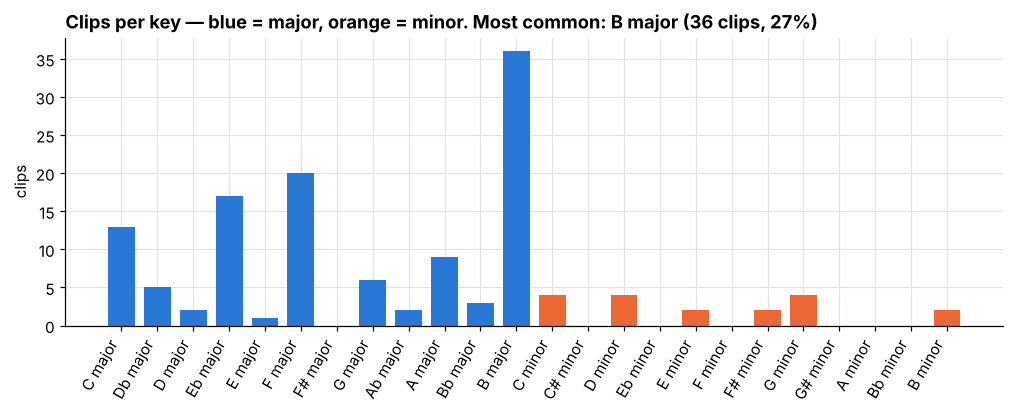

In [5]:
counts = pd.Series(y).value_counts().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(24), counts, color=[BLUE] * 12 + [ORANGE] * 12, width=0.75)
ax.set_xticks(range(24), KEY_NAMES, rotation=60, ha="right"); ax.set_ylabel("clips")
ax.set_title(f"Clips per key — blue = major, orange = minor. Most common: {KEY_NAMES[counts.idxmax()]} "
             f"({counts.max()} clips, {counts.max()/len(y):.0%})")
plt.show()

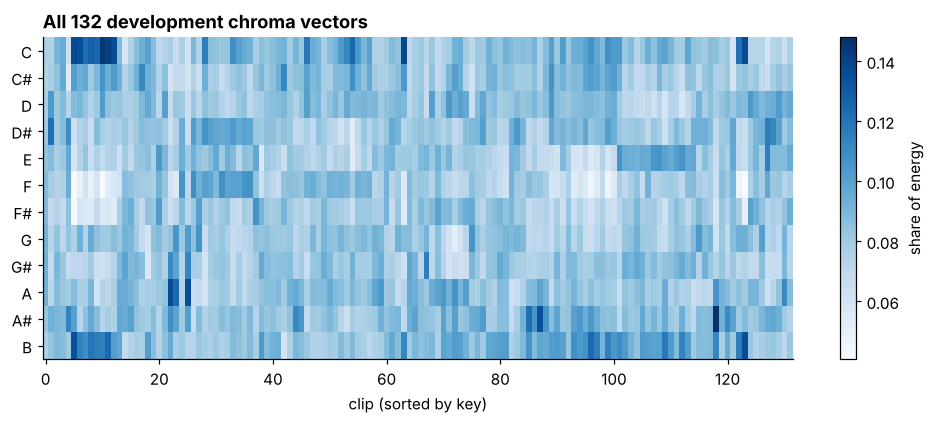

In [6]:
order = np.argsort(y, kind="stable")
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(X[order].T, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(range(12), PCS); ax.set_xlabel("clip (sorted by key)"); ax.grid(False)
ax.set_title("All 132 development chroma vectors")
fig.colorbar(im, ax=ax, label="share of energy")
plt.show()

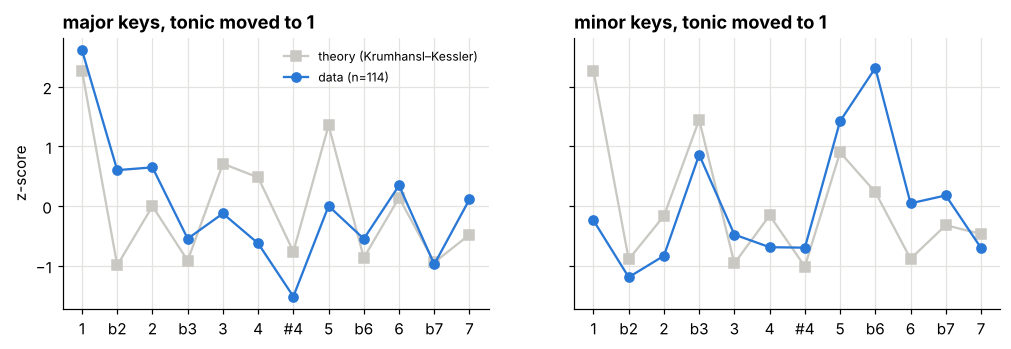

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
degrees = ["1", "b2", "2", "b3", "3", "4", "#4", "5", "b6", "6", "b7", "7"]
z = lambda v: (v - v.mean()) / v.std()
for ax, m, prof in [(axes[0], "major", KK_MAJOR), (axes[1], "minor", KK_MINOR)]:
    mask = (dev["mode"] == m).to_numpy()
    aligned = np.mean([np.roll(x, -(k % 12)) for x, k in zip(X[mask], y[mask])], axis=0)
    ax.plot(z(prof), color=GRAY, marker="s", label="theory (Krumhansl–Kessler)")
    ax.plot(z(aligned), color=BLUE, marker="o", label=f"data (n={mask.sum()})")
    ax.set_xticks(range(12), degrees); ax.set_title(f"{m} keys, tonic moved to 1")
axes[0].set_ylabel("z-score"); axes[0].legend(fontsize=8)
plt.show()

In [8]:
def cosine(A, B):
    A, B = np.atleast_2d(A), np.atleast_2d(B)
    return (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B / np.linalg.norm(B, axis=1, keepdims=True)).T

def centre(A):
    A = np.atleast_2d(A)
    return A - A.mean(axis=1, keepdims=True)

def transpose_all(Xt, yt):
    Xs = np.vstack([np.roll(Xt, s, axis=1) for s in range(12)])
    ys = np.concatenate([(yt % 12 + s) % 12 + 12 * (yt >= 12) for s in range(12)])
    return Xs, ys

def validate(method):
    pred = np.zeros_like(y)
    for s in np.unique(songs):
        held = songs == s
        pred[held] = method(X[~held], y[~held], X[held])
    return pred

MODELS = {}
VAL = {}

def majority(Xt, yt, Xq):
    return np.full(len(Xq), np.bincount(yt).argmax())

MODELS["baseline: most common key"] = majority
VAL["baseline: most common key"] = score(validate(majority), y)
pd.DataFrame(VAL).T

,accuracy,MIREX
baseline: most common key,0.273,0.28


# 3 · Cosine similarity

In [9]:
c = np.array([0, 0, 0, 1, 2.9, 0, 1, 1.2, 0, 1, 0, 1.4])
raw_cos = cosine(c, TEMPLATES)[0]
cen_cos = cosine(centre(c), centre(TEMPLATES))[0]
top = np.argsort(-cen_cos)[:5]
pd.DataFrame({"key": [KEY_NAMES[k] for k in top], "cosine (raw)": raw_cos[top], "cosine (centred)": cen_cos[top]})

,key,cosine (raw),cosine (centred)
0,E minor,0.805,0.856
1,E major,0.788,0.719
2,B major,0.718,0.453
3,A major,0.713,0.432
4,G major,0.671,0.271


All chroma values and template values are positive, so the raw cosine is high for *every* key.
Subtracting each vector's mean first (centring) removes this shared part, and E minor wins clearly.

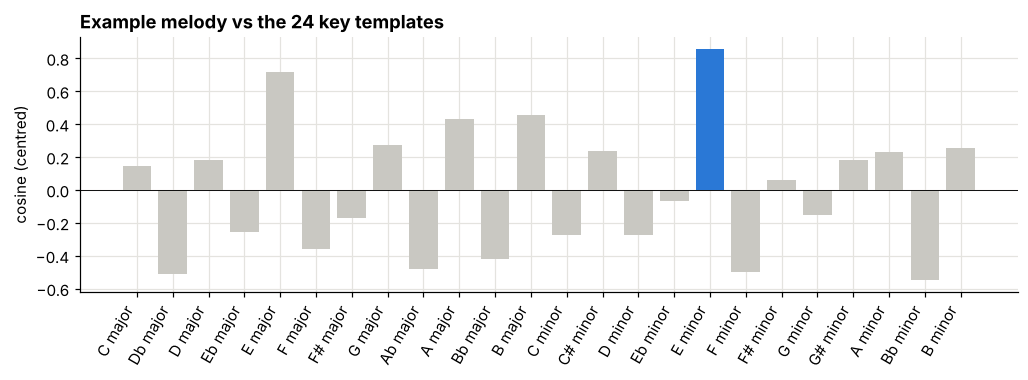

In [10]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.bar(range(24), cen_cos, color=[BLUE if k == top[0] else GRAY for k in range(24)])
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(range(24), KEY_NAMES, rotation=60, ha="right"); ax.set_ylabel("cosine (centred)")
ax.set_title("Example melody vs the 24 key templates")
plt.show()

In [11]:
def cos_templates_raw(Xt, yt, Xq):
    return cosine(Xq, TEMPLATES).argmax(axis=1)

def cos_templates(Xt, yt, Xq):
    return cosine(centre(Xq), centre(TEMPLATES)).argmax(axis=1)

def knn_vote(S, labels, k):
    pred = []
    for row in S:
        nn = np.argsort(-row)[:k]
        pred.append(np.bincount(labels[nn], weights=row[nn], minlength=24).argmax())
    return np.array(pred)

def cos_knn(Xt, yt, Xq, k=5):
    Xt, yt = transpose_all(Xt, yt)
    return knn_vote(cosine(centre(Xq), centre(Xt)), yt, k)

for name, m in [("cosine templates (raw)", cos_templates_raw), ("cosine templates (centred)", cos_templates),
                ("cosine 5-NN", cos_knn)]:
    MODELS[name] = m
    VAL[name] = score(validate(m), y)
pd.DataFrame(VAL).T

,accuracy,MIREX
baseline: most common key,0.273,0.280
cosine templates (raw),0.023,0.145
cosine templates (centred),0.106,0.214
cosine 5-NN,0.182,0.283


# 4 · TF-IDF

,C,C#,D,D#,E,F,F#,G,G#,A,A#,B
DF (clips where prominent),77.000,65.000,73.000,58.000,51.000,46.00,36.000,59.000,52.00,64.000,82.000,81.000
IDF,1.534,1.701,1.586,1.813,1.939,2.04,2.279,1.796,1.92,1.716,1.472,1.484


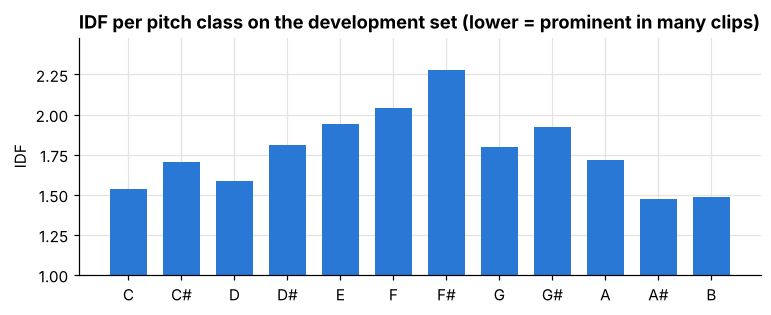

IDF after transposing (every class equally common): [1.755 1.755 1.755 1.755 1.755 1.755 1.755 1.755 1.755 1.755 1.755 1.755]


In [12]:
def idf_weights(Xt):
    N = len(Xt)
    DF = (Xt > Xt.mean(axis=1, keepdims=True)).sum(axis=0)
    return np.log((1 + N) / (1 + DF)) + 1, DF

idf, DF = idf_weights(X)
display(pd.DataFrame({"DF (clips where prominent)": DF, "IDF": idf}, index=PCS).T)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(PCS, idf, color=BLUE, width=0.7)
ax.set_ylim(1, idf.max() + 0.2); ax.set_ylabel("IDF")
ax.set_title("IDF per pitch class on the development set (lower = prominent in many clips)")
plt.show()
print("IDF after transposing (every class equally common):", idf_weights(transpose_all(X, y)[0])[0].round(3))

In [13]:
def tfidf_templates(Xt, yt, Xq):
    w, _ = idf_weights(Xt)
    return cosine(centre(Xq * w), centre(TEMPLATES * w)).argmax(axis=1)

def cos_knn_plain(Xt, yt, Xq, k=5):
    return knn_vote(cosine(centre(Xq), centre(Xt)), yt, k)

def tfidf_knn(Xt, yt, Xq, k=5):
    w, _ = idf_weights(Xt)
    return knn_vote(cosine(centre(Xq * w), centre(Xt * w)), yt, k)

for name, m in [("TF-IDF + cosine templates", tfidf_templates),
                ("cosine 5-NN, no transposition", cos_knn_plain),
                ("TF-IDF + cosine 5-NN, no transposition", tfidf_knn)]:
    MODELS[name] = m
    VAL[name] = score(validate(m), y)
pd.DataFrame(VAL).T

,accuracy,MIREX
baseline: most common key,0.273,0.280
cosine templates (raw),0.023,0.145
cosine templates (centred),0.106,0.214
cosine 5-NN,0.182,0.283
TF-IDF + cosine templates,0.038,0.123
"cosine 5-NN, no transposition",0.061,0.092
"TF-IDF + cosine 5-NN, no transposition",0.076,0.099


# 5 · Linear regression

In [14]:
def design(Xq):
    return np.column_stack([np.ones(len(Xq)), Xq[:, :-1]])

def linreg_fit(Xt, yt):
    Xt, yt = transpose_all(Xt, yt)
    Z = design(Xt)
    return np.linalg.solve(Z.T @ Z, Z.T @ np.eye(24)[yt])

def linreg(Xt, yt, Xq):
    return (design(Xq) @ linreg_fit(Xt, yt)).argmax(axis=1)

MODELS["linear regression"] = linreg
VAL["linear regression"] = score(validate(linreg), y)
pd.DataFrame(VAL).T

,accuracy,MIREX
baseline: most common key,0.273,0.280
cosine templates (raw),0.023,0.145
cosine templates (centred),0.106,0.214
cosine 5-NN,0.182,0.283
TF-IDF + cosine templates,0.038,0.123
"cosine 5-NN, no transposition",0.061,0.092
"TF-IDF + cosine 5-NN, no transposition",0.076,0.099
linear regression,0.326,0.381


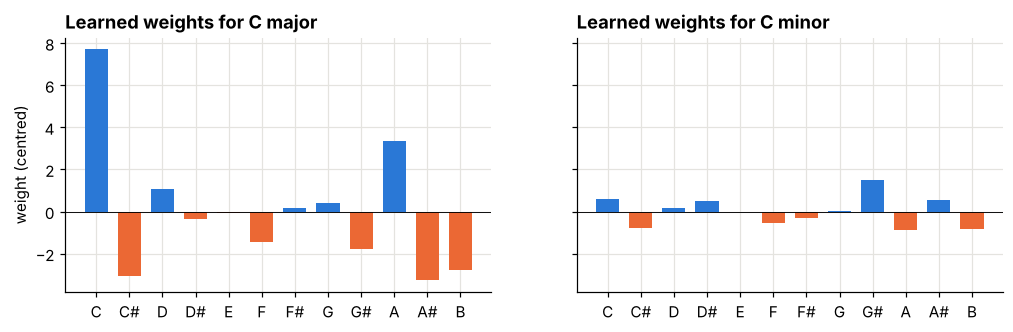

In [15]:
B_dev = linreg_fit(X, y)
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, k in [(axes[0], 0), (axes[1], 12)]:
    w = np.append(B_dev[1:, k], 0)
    w = w - w.mean()
    ax.bar(PCS, w, color=[BLUE if v > 0 else ORANGE for v in w], width=0.7)
    ax.axhline(0, color="black", lw=0.6); ax.set_title(f"Learned weights for {KEY_NAMES[k]}")
axes[0].set_ylabel("weight (centred)")
plt.show()

The weights look like music theory: for C major the tonic C has the largest weight and the notes outside
the C major scale get negative weights.

# 6 · Principal Component Analysis (PCA)

explained variance: [39.8 19.4 10.6  9.5  6.4] % ...   check Σv = λv: True


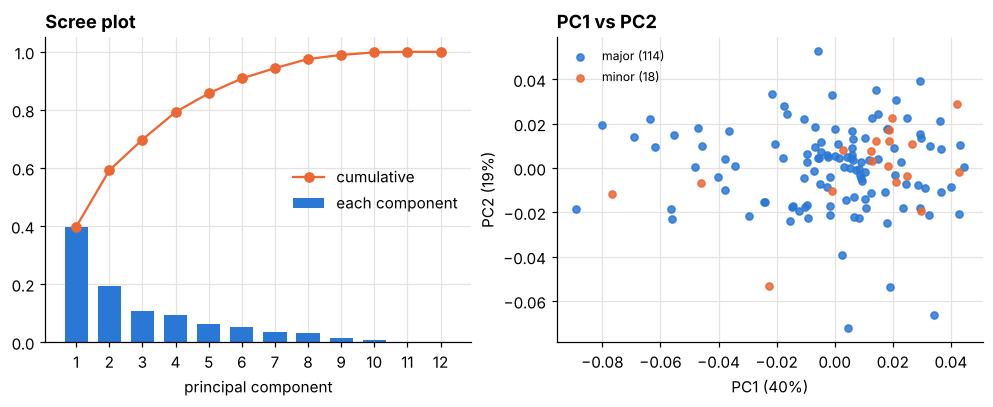

In [16]:
X0 = X - X.mean(axis=0)
Sigma = X0.T @ X0 / (len(X) - 1)
lam, V = np.linalg.eigh(Sigma)
lam, V = lam[::-1], V[:, ::-1]
explained = lam / lam.sum()
print("explained variance:", (explained[:5] * 100).round(1), "% ...   check Σv = λv:", np.allclose(Sigma @ V, V * lam))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(1, 13), explained, color=BLUE, width=0.7, label="each component")
axes[0].plot(range(1, 13), np.cumsum(explained), color=ORANGE, marker="o", label="cumulative")
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("principal component"); axes[0].set_title("Scree plot")
axes[0].legend()
P2 = X0 @ V[:, :2]
for g, colr in [("major", BLUE), ("minor", ORANGE)]:
    m = (dev["mode"] == g).to_numpy()
    axes[1].scatter(P2[m, 0], P2[m, 1], s=22, color=colr, alpha=0.85, label=f"{g} ({m.sum()})")
axes[1].set_xlabel(f"PC1 ({explained[0]:.0%})"); axes[1].set_ylabel(f"PC2 ({explained[1]:.0%})")
axes[1].set_title("PC1 vs PC2"); axes[1].legend(fontsize=8)
plt.show()

### 6.1 · PCA + linear regression — choose *m* on the validation set

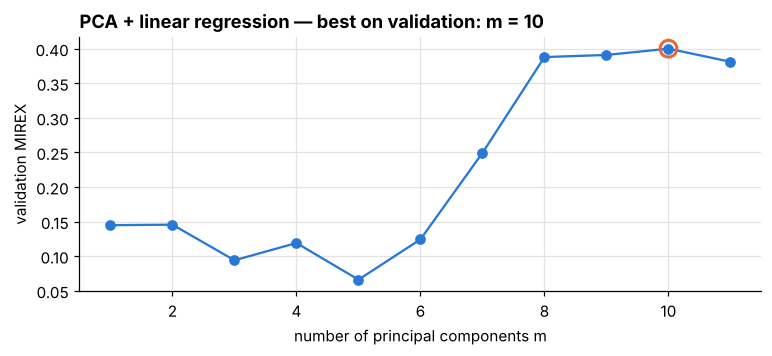

In [17]:
def pca_linreg(m):
    def predict(Xt, yt, Xq):
        Xt, yt = transpose_all(Xt, yt)
        mu = Xt.mean(axis=0)
        _, Vt = np.linalg.eigh(np.cov((Xt - mu).T))
        Vm = Vt[:, ::-1][:, :m]
        Zt = np.column_stack([np.ones(len(Xt)), (Xt - mu) @ Vm])
        B = np.linalg.solve(Zt.T @ Zt, Zt.T @ np.eye(24)[yt])
        return (np.column_stack([np.ones(len(Xq)), (Xq - mu) @ Vm]) @ B).argmax(axis=1)
    return predict

sweep = {m: score(validate(pca_linreg(m)), y)["MIREX"] for m in range(1, 12)}
best_m = max(sweep, key=sweep.get)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(list(sweep), list(sweep.values()), color=BLUE, marker="o")
ax.scatter([best_m], [sweep[best_m]], s=120, facecolor="none", edgecolor=ORANGE, lw=2, zorder=3)
ax.set_xlabel("number of principal components m"); ax.set_ylabel("validation MIREX")
ax.set_title(f"PCA + linear regression — best on validation: m = {best_m}")
plt.show()

for m in sorted({2, best_m}):
    MODELS[f"PCA ({m} comp.) + linear regression"] = pca_linreg(m)
    VAL[f"PCA ({m} comp.) + linear regression"] = score(validate(pca_linreg(m)), y)

# 7 · Validation results → choose the final model

,accuracy,MIREX
PCA (10 comp.) + linear regression,0.348,0.400
linear regression,0.326,0.381
cosine 5-NN,0.182,0.283
baseline: most common key,0.273,0.280
cosine templates (centred),0.106,0.214
PCA (2 comp.) + linear regression,0.121,0.145
cosine templates (raw),0.023,0.145
TF-IDF + cosine templates,0.038,0.123
"TF-IDF + cosine 5-NN, no transposition",0.076,0.099
"cosine 5-NN, no transposition",0.061,0.092


chosen model (highest validation MIREX): PCA (10 comp.) + linear regression


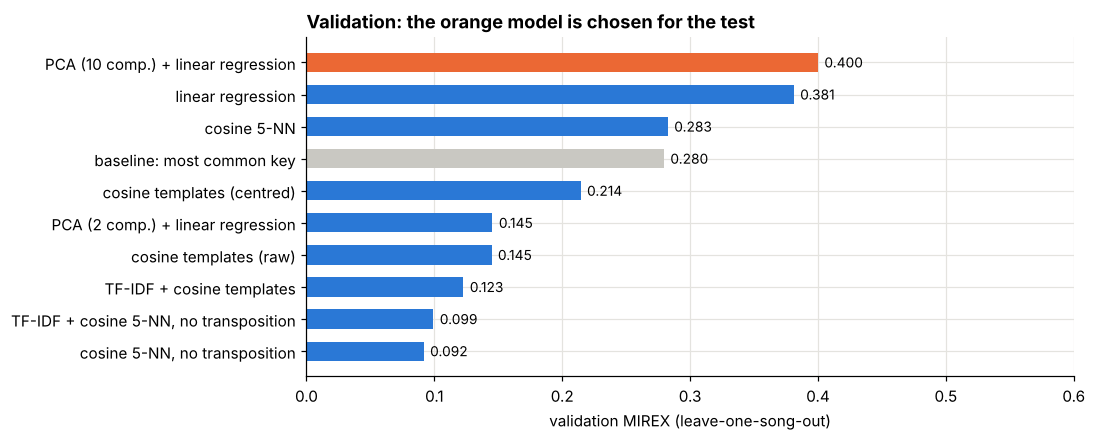

In [18]:
val_table = pd.DataFrame(VAL).T.sort_values("MIREX", ascending=False)
BEST = val_table.index[0]
display(val_table)
print("chosen model (highest validation MIREX):", BEST)

fig, ax = plt.subplots(figsize=(9, 4))
cols = [ORANGE if n == BEST else (GRAY if "baseline" in n else BLUE) for n in val_table.index]
ax.barh(val_table.index, val_table.MIREX, color=cols, height=0.6)
for i, v in enumerate(val_table.MIREX):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("validation MIREX (leave-one-song-out)"); ax.set_xlim(0, 0.6)
ax.set_title("Validation: the orange model is chosen for the test")
plt.show()

# 8 · Final test on 40 real recordings (vocadito)

In [19]:
for VOC in ["vocadito", "data/vocadito", "../vocadito", "../data/vocadito"]:
    if os.path.isdir(os.path.join(VOC, "Audio")):
        break
else:
    raise FileNotFoundError("Unzip the vocadito folder next to this notebook (vocadito/Audio/*.wav).")

meta = pd.read_csv(os.path.join(VOC, "vocadito_metadata.csv"))
meta["clip_id"] = "vocadito_" + meta.track_id.astype(str)
test = test_labels[["clip_id", "key", "y"]].merge(meta[["clip_id", "singer_id", "language"]], on="clip_id")
print(f"{len(test)} test recordings, {test.singer_id.nunique()} singers, languages: {sorted(test.language.unique())}")

def chroma_from_audio(x, sr):
    if sr != 22050:
        x = librosa.resample(x, orig_sr=sr, target_sr=22050)
    return l1(librosa.feature.chroma_stft(y=x, sr=22050).mean(axis=1))[0]

def load_audio(path):
    x, sr = librosa.load(path, sr=22050)
    return x, sr

if HAS_LIBROSA:
    X_test = np.array([chroma_from_audio(*load_audio(os.path.join(VOC, "Audio", f"{cid}.wav")))
                       for cid in test.clip_id])
else:
    X_test = l1(test_labels.set_index("clip_id").loc[test.clip_id, PCS])
    print("librosa missing: using the CSV chroma for the test clips instead")
y_test = test.y.to_numpy()

check = l1(test_labels.set_index("clip_id").loc[test.clip_id, PCS])
print("largest difference between chroma from audio and chroma in the CSV:", round(float(np.abs(X_test - check).max()), 6))

40 test recordings, 29 singers, languages: ['Catalan/Valencian', 'English', 'French', 'French+English', 'Hawaiian+English', 'Mandarin', 'Spanish', 'Tagalog', 'none']


largest difference between chroma from audio and chroma in the CSV: 0.0


In [20]:
pred_test = {name: m(X, y, X_test) for name, m in MODELS.items()}
TEST = {name: score(p, y_test) for name, p in pred_test.items()}

both = pd.DataFrame({"validation MIREX": {n: v["MIREX"] for n, v in VAL.items()},
                     "test accuracy": {n: v["accuracy"] for n, v in TEST.items()},
                     "test MIREX": {n: v["MIREX"] for n, v in TEST.items()}}).loc[val_table.index]
display(both)
print(f"FINAL RESULT — chosen model '{BEST}': test accuracy {TEST[BEST]['accuracy']:.3f}, "
      f"test MIREX {TEST[BEST]['MIREX']:.3f}")

,validation MIREX,test accuracy,test MIREX
PCA (10 comp.) + linear regression,0.400,0.275,0.325
linear regression,0.381,0.275,0.325
cosine 5-NN,0.283,0.125,0.150
baseline: most common key,0.280,0.125,0.163
cosine templates (centred),0.214,0.275,0.383
PCA (2 comp.) + linear regression,0.145,0.100,0.110
cosine templates (raw),0.145,0.175,0.270
TF-IDF + cosine templates,0.123,0.350,0.447
"TF-IDF + cosine 5-NN, no transposition",0.099,0.050,0.107
"cosine 5-NN, no transposition",0.092,0.125,0.188


FINAL RESULT — chosen model 'PCA (10 comp.) + linear regression': test accuracy 0.275, test MIREX 0.325


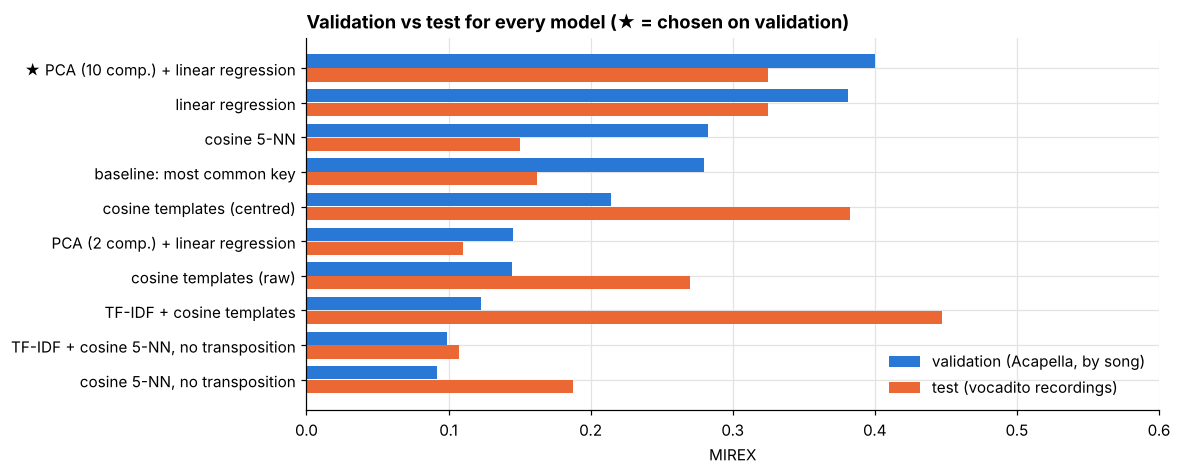

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.4))
yy = np.arange(len(both))
ax.barh(yy - 0.2, both["validation MIREX"], height=0.38, color=BLUE, label="validation (Acapella, by song)")
ax.barh(yy + 0.2, both["test MIREX"], height=0.38, color=ORANGE, label="test (vocadito recordings)")
ax.set_yticks(yy, [("★ " if n == BEST else "") + n for n in both.index]); ax.invert_yaxis()
ax.set_xlabel("MIREX"); ax.set_xlim(0, 0.6); ax.legend(loc="lower right")
ax.set_title("Validation vs test for every model (★ = chosen on validation)")
plt.show()

,clip_id,singer_id,language,key,predicted,result
0,vocadito_1,S1,Tagalog,Bb major,D major,other
1,vocadito_4,S3,Catalan/Valencian,D minor,D major,parallel
2,vocadito_5,S4,Catalan/Valencian,B major,A major,other
3,vocadito_6,S5,English,Db major,B major,other
4,vocadito_9,S6,Tagalog,E minor,Eb major,other
5,vocadito_10,S7,English,B major,Bb major,other
6,vocadito_12,S9,English,B major,B major,correct
7,vocadito_13,S10,French,C# minor,C major,other
8,vocadito_14,S11,English,B major,B major,correct
9,vocadito_15,S12,English,G# minor,Ab major,parallel


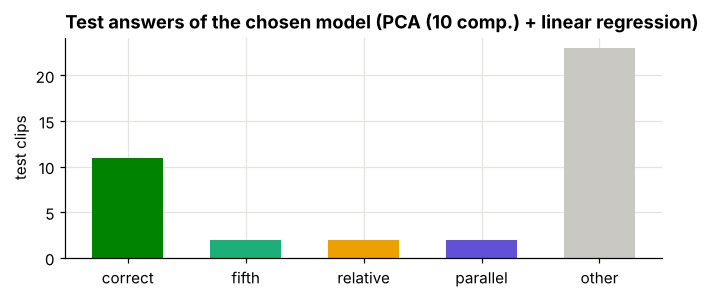

In [22]:
def relation(p, t):
    return {1.0: "correct", 0.5: "fifth", 0.3: "relative", 0.2: "parallel", 0.0: "other"}[mirex(p, t)]

p_best = pred_test[BEST]
per_clip = test[["clip_id", "singer_id", "language", "key"]].copy()
per_clip["predicted"] = [KEY_NAMES[k] for k in p_best]
per_clip["result"] = [relation(p, t) for p, t in zip(p_best, y_test)]
display(per_clip)

counts = per_clip.result.value_counts().reindex(["correct", "fifth", "relative", "parallel", "other"], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(counts.index, counts.values, color=[GREEN, AQUA, YELLOW, VIOLET, GRAY], width=0.6)
ax.set_ylabel("test clips"); ax.set_title(f"Test answers of the chosen model ({BEST})")
plt.show()

### 8.1 · Listen to two test recordings

In [23]:
for label, idx in [("a correct answer", np.where(p_best == y_test)[0]),
                   ("a wrong answer", np.where(p_best != y_test)[0])]:
    if len(idx) == 0:
        continue
    i = idx[0]
    x, sr = load_audio(os.path.join(VOC, "Audio", f"{test.clip_id[i]}.wav")) if HAS_LIBROSA else (None, None)
    print(f"{label}: {test.clip_id[i]}  true = {test.key[i]}, predicted = {KEY_NAMES[p_best[i]]}")
    if x is not None:
        display(Audio(x[: 10 * sr], rate=sr))

a correct answer: vocadito_12  true = B major, predicted = B major


a wrong answer: vocadito_1  true = Bb major, predicted = D major


# 9 · Try it: classify a new sound

In [24]:
SR = 22050
MAJOR_STEPS = [0, 2, 4, 5, 7, 9, 11]
MINOR_STEPS = [0, 2, 3, 5, 7, 8, 11]

def random_melody(key, n_notes=16, note_sec=0.3, rng=None, noise=0.02):
    rng = rng if rng is not None else np.random.default_rng()
    steps = MINOR_STEPS if key >= 12 else MAJOR_STEPS
    weights = np.array([4, 1.5, 2.5, 1.5, 3, 1.5, 1.2])
    degrees = rng.choice(7, size=n_notes, p=weights / weights.sum())
    degrees[0] = degrees[-1] = 0
    midi = 60 + key % 12 + np.array(steps)[degrees]
    midi = np.where(midi > 72, midi - 12, midi)
    t = np.arange(int(SR * note_sec)) / SR
    notes = []
    for m in midi:
        f = 440 * 2 ** ((m - 69 + rng.normal(0, 0.15)) / 12)
        phase = 2 * np.pi * f * t + 0.6 * np.sin(2 * np.pi * 5.5 * t)
        tone = sum(a * np.sin(h * phase) for h, a in [(1, 1), (2, .5), (3, .25), (4, .12)])
        notes.append(tone * np.minimum(1, np.minimum(t / 0.03, (note_sec - t) / 0.05)))
    x = np.concatenate(notes)
    return (x / np.abs(x).max() + noise * rng.normal(size=len(x))).astype(np.float32)

B_final = linreg_fit(X, y)

def classify(c, k=3):
    c = l1(c)
    cos_scores = cosine(centre(c), centre(TEMPLATES))[0]
    lr_scores = (design(c) @ B_final)[0]
    top_cos, top_lr = np.argsort(-cos_scores)[:k], np.argsort(-lr_scores)[:k]
    return pd.DataFrame({"cosine templates": [f"{KEY_NAMES[i]} ({cos_scores[i]:.2f})" for i in top_cos],
                         "linear regression": [f"{KEY_NAMES[i]} ({lr_scores[i]:.2f})" for i in top_lr]},
                        index=["1st", "2nd", "3rd"])

In [25]:
rng = np.random.default_rng()
true_key = int(rng.integers(24))
x = random_melody(true_key, rng=rng)
print("true key:", KEY_NAMES[true_key])
display(Audio(x, rate=SR))
display(classify(chroma_from_audio(x, SR)) if HAS_LIBROSA else "install librosa first")

true key: E minor


,cosine templates,linear regression
1st,E minor (0.71),E major (1.31)
2nd,B major (0.61),B major (0.79)
3rd,E major (0.56),G# minor (0.42)


In [26]:
if HAS_LIBROSA:
    rng = np.random.default_rng(42)
    keys200 = rng.integers(24, size=200)
    C200 = np.array([chroma_from_audio(random_melody(k, rng=rng), SR) for k in keys200])
    display(pd.DataFrame({"cosine templates": score(cos_templates(X, y, C200), keys200),
                          "linear regression": score(linreg(X, y, C200), keys200)}).T)
    print("peakedness (max / mean):  development", round(float((X.max(1) / X.mean(1)).mean()), 2),
          "| random melodies", round(float((C200.max(1) / C200.mean(1)).mean()), 2))

,accuracy,MIREX
cosine templates,0.83,0.862
linear regression,0.43,0.546


peakedness (max / mean):  development 1.28 | random melodies 2.84


In [27]:
def classify_wav(path):
    x, sr = load_audio(path)
    display(Audio(x, rate=sr))
    return classify(chroma_from_audio(x, sr))

# classify_wav("my_singing.wav")